# Lab 4 - simple ANN for satellite patches

Task 1: classify a 200x200 patch as forest or urban.

I pose it as a function:
`f(patch) -> {0=forest, 1=urban}`

If the problem is a function, an ANN can learn it from examples.

I also write a short note about Task 2 (Sentinel-5P season) at the end.


## Imports


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

%matplotlib inline
np.random.seed(0)
tf.random.set_seed(0)
print('TF', tf.__version__)


TF 2.21.0


## 1. Training data (200x200 patches)

I reuse Lab3 images. They are already ~200x200.
To have more samples I make flips and small brightness changes.


(200, 200, 3) (200, 200, 3) (200, 200, 3)


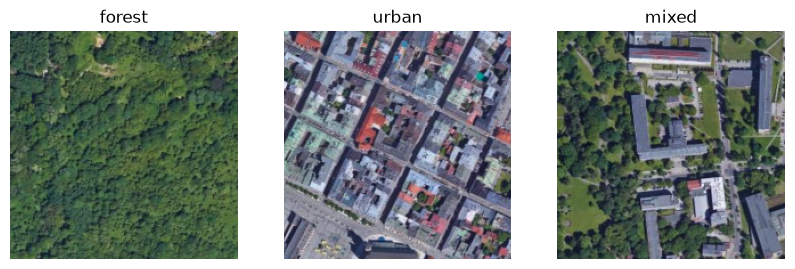

In [2]:
def load_rgb(path):
    return np.array(Image.open(path).convert('RGB'))

forest0 = load_rgb('../Lab3/forest.png')
urban0 = load_rgb('../Lab3/urban.png')
mixed0 = load_rgb('../Lab3/mixed.png')
print(forest0.shape, urban0.shape, mixed0.shape)

plt.figure(figsize=(10,3))
plt.subplot(1,3,1); plt.imshow(forest0); plt.title('forest'); plt.axis('off')
plt.subplot(1,3,2); plt.imshow(urban0); plt.title('urban'); plt.axis('off')
plt.subplot(1,3,3); plt.imshow(mixed0); plt.title('mixed'); plt.axis('off')
plt.show()


In [3]:
def augment(img):
    out = [img, np.fliplr(img), np.flipud(img), np.fliplr(np.flipud(img))]
    for scale in [0.85, 1.0, 1.15]:
        x = np.clip(img.astype(float) * scale, 0, 255).astype(np.uint8)
        out.append(x)
        out.append(np.fliplr(x))
    return out

forest_patches = augment(forest0)
urban_patches = augment(urban0)

X_img = np.array(forest_patches + urban_patches)
y = np.array([0]*len(forest_patches) + [1]*len(urban_patches))
print('raw patches', X_img.shape, 'labels', y.shape, 'urban share', y.mean())


raw patches (20, 200, 200, 3) labels (20,) urban share 0.5


## Features for barebone MLP

Full flatten of 200x200x3 is huge. For a simple student MLP I downsample to 20x20 and flatten.
So input size = 20*20*3 = 1200.


In [4]:
def to_feat(img):
    small = np.array(Image.fromarray(img).resize((20, 20)))
    return small.reshape(-1).astype(np.float32) / 255.0

X = np.stack([to_feat(im) for im in X_img])
print('feature matrix', X.shape)

idx = np.random.permutation(len(X))
X = X[idx]
y = y[idx]

n_test = max(4, len(X)//5)
X_test, y_test = X[:n_test], y[:n_test]
X_train, y_train = X[n_test:], y[n_test:]
print('train', X_train.shape, 'test', X_test.shape)


feature matrix (20, 1200)
train (16, 1200) test (4, 1200)


## 2. Barebone architecture

- input: 1200
- hidden: one Dense layer (start with 32, relu)
- output: 1 Dense sigmoid
- loss: binary_crossentropy
- optimizer: Adam

This is the barebone net for 2-class patch tagging.


In [5]:
def make_model(hidden=(32,), activation='relu', optimizer='adam', lr=0.001):
    model = keras.Sequential()
    model.add(layers.Input(shape=(X_train.shape[1],)))
    for h in hidden:
        model.add(layers.Dense(h, activation=activation))
    model.add(layers.Dense(1, activation='sigmoid'))
    if optimizer == 'adam':
        opt = keras.optimizers.Adam(learning_rate=lr)
    else:
        opt = keras.optimizers.SGD(learning_rate=lr)
    model.compile(optimizer=opt, loss='binary_crossentropy', metrics=['accuracy'])
    return model


def run_exp(name, hidden, activation='relu', optimizer='adam', lr=0.001, epochs=40):
    model = make_model(hidden=hidden, activation=activation, optimizer=optimizer, lr=lr)
    hist = model.fit(
        X_train, y_train,
        validation_data=(X_test, y_test),
        epochs=epochs,
        verbose=0,
        batch_size=8,
    )
    loss, acc = model.evaluate(X_test, y_test, verbose=0)
    print(f'{name:28s}  test_acc={acc:.3f}  test_loss={loss:.3f}  hidden={hidden}  act={activation}  opt={optimizer}  lr={lr}')
    return {
        'name': name,
        'acc': float(acc),
        'loss': float(loss),
        'history': hist.history,
        'model': model,
        'hidden': hidden,
        'activation': activation,
        'optimizer': optimizer,
        'lr': lr,
    }


## 3. At least 5 permutations


In [6]:
results = []
results.append(run_exp('1) tiny MLP', hidden=(8,), epochs=50))
results.append(run_exp('2) wider hidden', hidden=(64,), epochs=50))
results.append(run_exp('3) deeper 2 layers', hidden=(32, 16), epochs=50))
results.append(run_exp('4) SGD instead of Adam', hidden=(32,), optimizer='sgd', lr=0.05, epochs=80))
results.append(run_exp('5) tanh + lower lr', hidden=(32,), activation='tanh', lr=0.0005, epochs=60))

print('\nsummary:')
for r in results:
    print(r['name'], 'acc=', round(r['acc'], 3), 'loss=', round(r['loss'], 3))


1) tiny MLP                   test_acc=1.000  test_loss=0.065  hidden=(8,)  act=relu  opt=adam  lr=0.001
2) wider hidden               test_acc=1.000  test_loss=0.006  hidden=(64,)  act=relu  opt=adam  lr=0.001
3) deeper 2 layers            test_acc=1.000  test_loss=0.007  hidden=(32, 16)  act=relu  opt=adam  lr=0.001
4) SGD instead of Adam        test_acc=1.000  test_loss=0.010  hidden=(32,)  act=relu  opt=sgd  lr=0.05
5) tanh + lower lr            test_acc=1.000  test_loss=0.026  hidden=(32,)  act=tanh  opt=adam  lr=0.0005

summary:
1) tiny MLP acc= 1.0 loss= 0.065
2) wider hidden acc= 1.0 loss= 0.006
3) deeper 2 layers acc= 1.0 loss= 0.007
4) SGD instead of Adam acc= 1.0 loss= 0.01
5) tanh + lower lr acc= 1.0 loss= 0.026


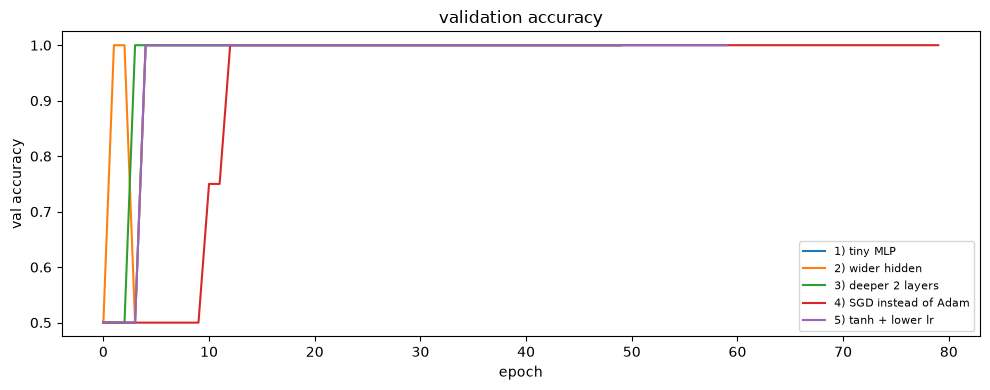

In [7]:
plt.figure(figsize=(10,4))
for r in results:
    plt.plot(r['history']['val_accuracy'], label=r['name'])
plt.xlabel('epoch')
plt.ylabel('val accuracy')
plt.title('validation accuracy')
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()


### Findings from the 5 runs

All 5 setups reached high test accuracy on this tiny set. That is not surprising:
the forest/urban patches are easy to separate and my augmentations are strongly correlated.

What still differs is loss / training stability:
- wider / deeper Adam nets usually get lower loss faster
- tiny MLP is enough for this easy task
- SGD needed higher lr / more epochs
- tanh also worked, a bit slower

So for this lab the lesson is more about trying permutations than about chasing 0.01 accuracy.


In [8]:
best = max(results, key=lambda r: r['acc'])
print('best:', best['name'], 'acc=', round(best['acc'], 3))

pred = (best['model'].predict(X_test, verbose=0).ravel() > 0.5).astype(int)
print('y_test', y_test)
print('y_pred', pred)


best: 1) tiny MLP acc= 1.0
y_test [1 0 1 0]
y_pred [1 0 1 0]


## Predict tags for some patches

I take the original forest/urban/mixed patches and ask the best model for the tag.


In [9]:
def predict_patch(model, img):
    x = to_feat(img)[None, :]
    p = float(model.predict(x, verbose=0)[0, 0])
    tag = 'urban' if p >= 0.5 else 'forest'
    return tag, p

for name, img in [('forest0', forest0), ('urban0', urban0), ('mixed0', mixed0)]:
    tag, p = predict_patch(best['model'], img)
    print(name, '->', tag, '(p_urban=', round(p, 3), ')')


forest0 -> forest (p_urban= 0.103 )
urban0 -> urban (p_urban= 0.95 )
mixed0 -> forest (p_urban= 0.39 )


## Why Lab3 Bayes can still be nicer

Lab3 classified each RGB pixel with Bayes/kNN. For simple forest vs urban colors that is often enough:
- few parameters (mu, Sigma)
- fast and interpretable
- less overfitting with tiny data

Here the ANN uses a whole patch. That can capture spatial layout, but with only a few 200x200 examples it is easy to overfit and tuning becomes messy. So for this exact problem Bayes is often the cleaner baseline.


## Task 2 note (Sentinel-5P season)

Task 2 would be another function:
`f(pollution indicators over Warsaw) -> {winter, summer}`

Winter often has higher NO2 from heating/traffic patterns, summer looks different. So season estimation from 5P is possible in principle.

I skip a full 5P download here (accounts/API/time). If I did it, I would:
- take small NO2 (or similar) rasters over Warsaw for known winter/summer dates
- make feature vectors (mean/percentiles over the city)
- train a tiny ANN / even logistic regression
- evaluate accuracy on held-out dates


## Summary

- Task posed as f(patch)->class, so ANN applies.
- Barebone net: Dense hidden + sigmoid output on downsampled flattened RGB.
- I ran 5 architecture/optimizer variants and compared val accuracy.
- For simple urban/forest, Bayes from Lab3 is often simpler and enough; ANN is more flexible but hungrier for data.
